# Isolation Forest — Unsupervised Fraud Detection Baseline

This notebook builds the first fraud-detection model for the project: an
**Isolation Forest** anomaly detector trained on the Kaggle Credit Card Fraud
Detection dataset.

It's the documented, narrative version of the training pipeline. The same logic
lives in `src/models/train_isolation_forest.py` as a reusable script — that's
what the FastAPI service will import later. This notebook exists to show the
reasoning and the results.

**Before running:** the dataset isn't committed to this repository (284k rows,
~150MB — raw data doesn't belong in git). Download `creditcard.csv` from
[Kaggle](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) and place it
at `data/raw/creditcard.csv` relative to the repository root.

---

## What an Isolation Forest actually does

Picture building a decision tree with no goal of predicting anything. It just
picks a random feature and a random cut-point between that feature's minimum
and maximum, splits the data in two, and repeats — until every single data
point sits alone in its own box.

Do that once and it means little. Build *hundreds* of such trees and something
useful emerges: a transaction sitting in a dense crowd of similar transactions
needs **many** random splits before it's separated from its neighbours. A
genuinely unusual transaction gets isolated almost immediately, because a
single random cut is likely to slice it away from everyone else — there's no
crowd around it to begin with.

So the **anomaly score** is simply: *on average across all the trees, how few
splits did it take to isolate this point?* Few splits means anomalous; many
splits means normal.

The appeal for fraud detection is that this makes no assumption about what
"normal" looks like statistically — it's a purely geometric idea. We never have
to specify in advance what fraud looks like.


## Setup

In [1]:
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    confusion_matrix,
    precision_recall_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler

RANDOM_STATE = 42  # fixed so results are reproducible run to run

# Colors from a validated colorblind-safe palette, consistent with 01_eda.ipynb
COLOR_NORMAL = "#2a78d6"
COLOR_FRAUD = "#e34948"
INK_PRIMARY, INK_SECONDARY, INK_MUTED, GRIDLINE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRIDLINE, "axes.labelcolor": INK_SECONDARY,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED, "text.color": INK_PRIMARY,
    "grid.color": GRIDLINE, "font.size": 11, "axes.grid": True,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
})


## 1. Load the data and remove duplicates

The exploratory analysis (`01_eda.ipynb`) flagged **1,081 exactly duplicated
rows** and left the decision of what to do about them to this stage. Here's the
decision, and the reasoning:

**Drop them, before splitting into train and test.** If a duplicated
transaction landed in the training set *and* its twin landed in the test set,
the model would be "tested" on a row it had already memorised during training.
That inflates the results in a way that would never hold up on genuinely new
data. This class of mistake is called **data leakage**, and it's one of the
most common ways a model looks great in development and disappoints in
production.


In [2]:
df = pd.read_csv("../data/raw/creditcard.csv")
n_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)

print(f"Loaded {n_before:,} rows")
print(f"Dropped {n_before - len(df):,} exact duplicates")
print(f"{len(df):,} rows remain, of which {df['Class'].sum()} are fraud "
      f"({100 * df['Class'].mean():.3f}%)")


Loaded 284,807 rows
Dropped 1,081 exact duplicates
283,726 rows remain, of which 473 are fraud (0.167%)


## 2. Choose the features

Two deliberate choices here, both worth explaining:

**`Time` is dropped.** It records seconds elapsed since the first transaction in
the dataset — effectively "how far into this particular 48-hour collection
window did this happen." That number carries no meaning outside this specific
dataset. A model that learned "late in the collection window is suspicious"
would have learned a coincidence of how the data was gathered, not anything
about fraud.

**`Amount` is kept but will need scaling** (next step). `V1`–`V28` are left
exactly as they are, because they came out of a PCA transformation already
roughly standardised — mean near 0, standard deviation near 1.


In [3]:
feature_cols = [c for c in df.columns if c.startswith("V")] + ["Amount"]
X = df[feature_cols].copy()
y = df["Class"].copy()

print(f"{len(feature_cols)} features: {feature_cols[:5]} ... {feature_cols[-3:]}")


29 features: ['V1', 'V2', 'V3', 'V4', 'V5'] ... ['V27', 'V28', 'Amount']


## 3. Split into train and test — and the key design decision

An unsupervised model doesn't use labels to learn, so why split at all? Because
we still need to measure whether it generalises. Evaluating on the same rows the
model was fitted to would tell us how well it memorised, not how well it
detects.

Now the decision that shapes what this model actually learns. There are two
reasonable approaches:

1. **Fully unsupervised** — fit on all training rows (fraud and normal mixed
   together, labels simply never shown to the model).
2. **Semi-supervised / "one-class"** — fit *only* on transactions known to be
   normal, then evaluate on held-out data containing both.

**We're using the second.** The reason is about what the model is being asked to
learn, not about convenience. In a real payments system you never possess a
clean, complete set of labelled fraud — patterns shift constantly, and labels
arrive late, after the money is gone. A model trained to recognise *known* fraud
examples mostly re-recognises those examples. A model trained on "here is what
normal looks like" can flag a fraud pattern nobody has ever catalogued. That
generalisation to novel fraud is the entire argument for taking the anomaly
detection route instead of straightforward supervised classification.

The split is **stratified**, meaning the ~0.17% fraud proportion is preserved in
both halves. Without that, random chance could easily hand the test set a wildly
unrepresentative number of fraud cases given how few there are.


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

# The key step: fit on known-normal rows only.
X_train_normal = X_train[y_train == 0]

print(f"Train split:  {len(X_train):,} rows ({y_train.sum()} fraud)")
print(f"Test split:   {len(X_test):,} rows ({y_test.sum()} fraud)")
print(f"Model fits on {len(X_train_normal):,} known-normal rows only")
print(f"  -> the {y_train.sum()} fraud rows in the training split are never shown to the model")


Train split:  226,980 rows (378 fraud)
Test split:   56,746 rows (95 fraud)
Model fits on 226,602 known-normal rows only
  -> the 378 fraud rows in the training split are never shown to the model


## 4. Scale `Amount` — and why it doesn't matter for this model

`V1`–`V28` are already on a comparable scale, but `Amount` runs from \$0 to
\$25,691. Common advice says a mismatch like this distorts any model, so
`Amount` must be scaled first.

**For Isolation Forest that advice doesn't hold, and it's worth knowing why.**
Each split picks a random cut-point *uniformly between a feature's current
minimum and maximum*. Stretching or shifting a feature linearly maps every
possible cut-point onto an exactly equivalent one, so the trees partition the
data identically. Tested directly on this pipeline: no scaling, RobustScaler
and StandardScaler all give a PR-AUC of 0.08502, identical to five decimal
places.

We scale anyway, for two reasons that do hold: the autoencoder planned for the
next phase is a neural network and *is* highly sensitive to input scale; and
the API will serve both models through one preprocessing path, which is
simpler and less error-prone than handling each model differently.

**Why `RobustScaler` rather than `StandardScaler`** (this matters for the
autoencoder): StandardScaler divides by the standard deviation — about 250
here, inflated by a handful of enormous transactions — which squashes the bulk
of ordinary transactions (roughly £5–£77) into a band about 0.3 units wide.
RobustScaler uses the median and interquartile range, which describe where the
data actually lives, so ordinary transactions keep their resolution. Extreme
values stay extreme either way.

The scaler is fitted on the *training* data only, then applied to the test
data. Fitting it on everything would let information about the test set leak
into preprocessing — a subtle version of the same leakage problem as the
duplicates.


In [5]:
scaler = RobustScaler()

X_train_scaled = X_train_normal.copy()
X_train_scaled["Amount"] = scaler.fit_transform(X_train_normal[["Amount"]])

X_test_scaled = X_test.copy()
X_test_scaled["Amount"] = scaler.transform(X_test[["Amount"]])

print("Amount before scaling:", X_train_normal["Amount"].describe()[["min", "50%", "max"]].to_dict())
print("Amount after scaling: ", X_train_scaled["Amount"].describe()[["min", "50%", "max"]].to_dict())


Amount before scaling: {'min': 0.0, '50%': 22.08, 'max': 19656.53}
Amount after scaling:  {'min': -0.30679449770737804, '50%': 0.0, 'max': 272.81436709740166}


## 5. Train the model

Two hyperparameters worth understanding:

- **`n_estimators=200`** — how many random trees make up the forest. More trees
  give a more stable average path length (and therefore a steadier score), with
  diminishing returns.
- **`max_samples=256`** — how many data points each individual tree is built
  from. This looks surprisingly small for a 227,000-row dataset, and that's
  deliberate: Isolation Forest works well on small subsamples because isolating
  an outlier doesn't require seeing every normal point, just enough of them to
  establish where the crowd is. It's a large part of why the algorithm is fast.

`contamination="auto"` is left at its default because we aren't going to use
it. That parameter exists to let scikit-learn pick a cutoff automatically, but
we'll choose our own threshold explicitly in the next step — a decision worth
making visible rather than leaving buried inside the model.


In [6]:
model = IsolationForest(
    n_estimators=200,
    max_samples=256,
    contamination="auto",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
model.fit(X_train_scaled)
print("Model trained.")


Model trained.


## 6. Score the test set

One detail that trips people up constantly: scikit-learn's `score_samples()`
returns **higher values for more normal points**. That's the opposite of what
the phrase "risk score" implies, so we flip the sign. From here on, **higher
means more suspicious**, which is how the FastAPI endpoint will report it later.


In [7]:
raw_scores = model.score_samples(X_test_scaled)
risk_scores = -raw_scores  # flip: higher now means more anomalous

print(f"Risk scores for {len(risk_scores):,} unseen test transactions")
print(f"  range: {risk_scores.min():.4f} to {risk_scores.max():.4f}")
print(f"  mean score, normal transactions: {risk_scores[y_test == 0].mean():.4f}")
print(f"  mean score, fraud transactions:  {risk_scores[y_test == 1].mean():.4f}")


Risk scores for 56,746 unseen test transactions
  range: 0.3478 to 0.7745
  mean score, normal transactions: 0.4057
  mean score, fraud transactions:  0.5725


## 7. Choosing a threshold — and why accuracy is the wrong lens

The model outputs a continuous score, but a fraud system has to make a binary
call: flag it or let it through. That requires a **threshold**, and choosing one
is a trade-off rather than a calculation:

- Set it **low** and you catch more fraud (**high recall**) but drown the review
  team in false alarms (**low precision**).
- Set it **high** and almost everything you flag is genuinely fraud (**high
  precision**) but plenty of fraud slips past (**low recall**).

The precision-recall curve below shows that entire trade-off at once. The
**PR-AUC** summarises it in a single number that doesn't depend on any
particular threshold.

Why not accuracy? With a 0.17% fraud rate, a model that mindlessly answers
"not fraud" every time scores **99.83% accurate** and catches nothing. Accuracy
is actively misleading here. For the same reason, PR-AUC is preferred over the
more familiar ROC-AUC: ROC curves look flatteringly good under severe class
imbalance because the enormous number of true negatives swamps the comparison.

For this notebook the threshold is picked to maximise F1 (the harmonic mean of
precision and recall). In a real deployment that choice would belong to the
business — driven by how many alerts a review team can handle per day, and the
relative cost of a missed fraud versus an annoyed customer.


In [8]:
precision, recall, thresholds = precision_recall_curve(y_test, risk_scores)
pr_auc = average_precision_score(y_test, risk_scores)

denom = precision[:-1] + recall[:-1]
with np.errstate(invalid="ignore", divide="ignore"):
    f1_scores = np.where(denom > 0, 2 * precision[:-1] * recall[:-1] / denom, 0)

best_idx = int(np.argmax(f1_scores))
best_threshold = thresholds[best_idx]
best_precision, best_recall, best_f1 = precision[best_idx], recall[best_idx], f1_scores[best_idx]

random_baseline = y_test.mean()  # PR-AUC of a no-skill model == the positive rate

print(f"PR-AUC:                 {pr_auc:.4f}")
print(f"Random-guess baseline:  {random_baseline:.4f}  (equal to the fraud rate)")
print(f"Improvement over random: {pr_auc / random_baseline:.1f}x")
print()
print(f"Chosen threshold: {best_threshold:.4f}")
print(f"  Precision: {best_precision:.4f}")
print(f"  Recall:    {best_recall:.4f}")
print(f"  F1:        {best_f1:.4f}")


PR-AUC:                 0.0850
Random-guess baseline:  0.0017  (equal to the fraud rate)
Improvement over random: 50.8x

Chosen threshold: 0.6516
  Precision: 0.1935
  Recall:    0.2526
  F1:        0.2192


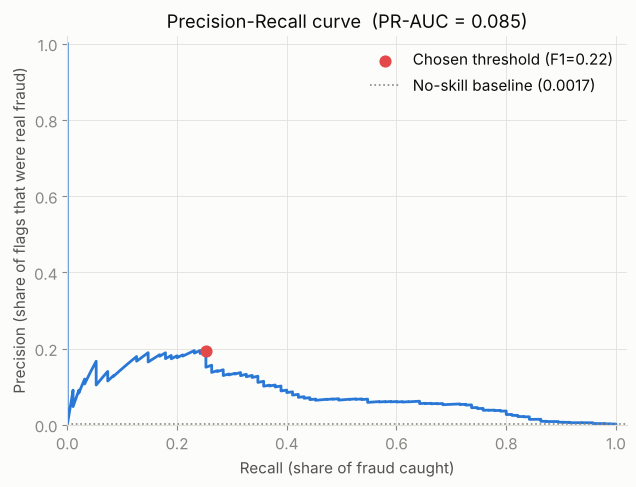

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot(recall, precision, color=COLOR_NORMAL, linewidth=2)
ax.scatter([best_recall], [best_precision], color=COLOR_FRAUD, s=60, zorder=5,
           label=f"Chosen threshold (F1={best_f1:.2f})")
ax.axhline(random_baseline, color=INK_MUTED, linestyle=":", linewidth=1.2,
           label=f"No-skill baseline ({random_baseline:.4f})")
ax.set_xlabel("Recall (share of fraud caught)")
ax.set_ylabel("Precision (share of flags that were real fraud)")
ax.set_title(f"Precision-Recall curve  (PR-AUC = {pr_auc:.3f})")
ax.set_xlim(0, 1.02)
ax.set_ylim(0, 1.02)
ax.legend(frameon=False, loc="upper right")
plt.tight_layout()
plt.show()


## 8. Confusion matrix

The same result expressed as raw counts — often the clearest way to communicate
what a fraud model actually does, because each cell maps to a real-world
consequence:

- **False negatives** (fraud we missed) cost money directly.
- **False positives** (legitimate transactions we flagged) cost customer trust
  and reviewer time.


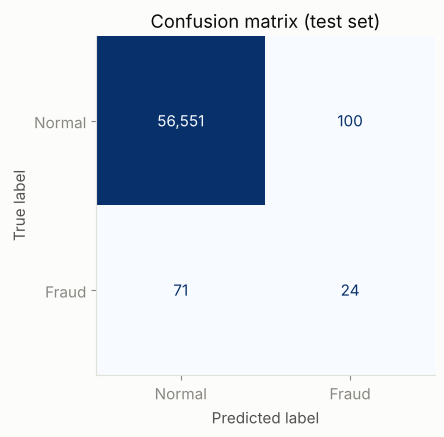

Of 95 real fraud cases, caught 24 and missed 71
Of 124 transactions flagged, 24 were genuinely fraud


In [10]:
y_pred = (risk_scores >= best_threshold).astype(int)
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal", "Fraud"]).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format=",d"
)
ax.set_title("Confusion matrix (test set)")
ax.grid(False)
plt.tight_layout()
plt.show()

print(f"Of {tp + fn} real fraud cases, caught {tp} and missed {fn}")
print(f"Of {tp + fp} transactions flagged, {tp} were genuinely fraud")


## 9. Did the model actually separate the two classes?

This is the most revealing plot in the notebook. It shows the risk scores the
model assigned to test transactions it had never seen, split by what they
actually turned out to be.

Remember: the model was never shown a single labelled fraud example. If the red
distribution sits meaningfully to the right of the blue one, the model learned
to recognise fraud purely from the shape of normal behaviour.


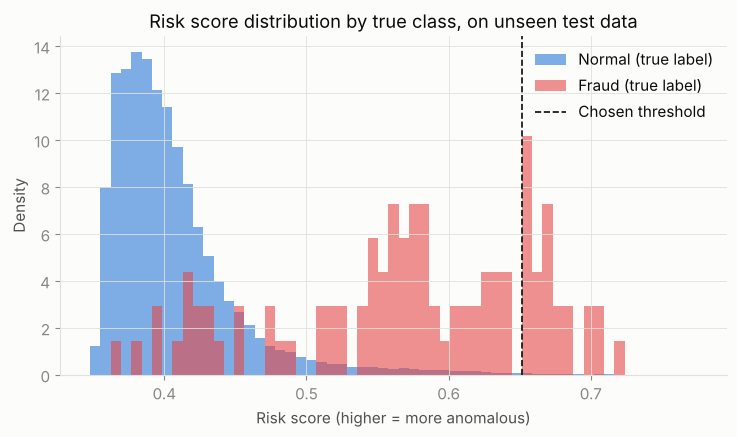

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
bins = np.linspace(risk_scores.min(), risk_scores.max(), 60)
ax.hist(risk_scores[y_test == 0], bins=bins, density=True, color=COLOR_NORMAL,
        alpha=0.6, label="Normal (true label)")
ax.hist(risk_scores[y_test == 1], bins=bins, density=True, color=COLOR_FRAUD,
        alpha=0.6, label="Fraud (true label)")
ax.axvline(best_threshold, color=INK_PRIMARY, linestyle="--", linewidth=1.2,
           label="Chosen threshold")
ax.set_xlabel("Risk score (higher = more anomalous)")
ax.set_ylabel("Density")
ax.set_title("Risk score distribution by true class, on unseen test data")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()


The separation is real but imperfect, and the overlap region is exactly where
the precision/recall trade-off lives. Every fraud case buried inside the blue
mass is one this approach cannot catch without flagging an unacceptable number
of legitimate transactions alongside it.


## 10. Save the model artifacts

In [12]:
from pathlib import Path

models_dir = Path("../models")
models_dir.mkdir(exist_ok=True)

joblib.dump(model, models_dir / "isolation_forest.joblib")
joblib.dump(scaler, models_dir / "isolation_forest_scaler.joblib")
joblib.dump(feature_cols, models_dir / "isolation_forest_features.joblib")

print("Saved: model, scaler, and feature list")
print("All three are needed at serving time — the API must preprocess incoming")
print("transactions exactly the way the training data was preprocessed.")


Saved: model, scaler, and feature list
All three are needed at serving time — the API must preprocess incoming
transactions exactly the way the training data was preprocessed.


## Summary and what comes next

| Metric | Value |
|---|---|
| PR-AUC | 0.085 |
| No-skill baseline | 0.0017 (the fraud rate) |
| Improvement over random | ~51x |
| Precision | 0.194 |
| Recall | 0.253 |
| F1 | 0.219 |

**How to read this honestly.** In absolute terms these numbers are modest — this
catches roughly a quarter of fraud, and three quarters of what it flags is a
false alarm. In context it's about 51 times better than chance, achieved by a
model that was never shown a labelled fraud case.

The gap between those two readings *is* the finding, and it's worth stating
plainly rather than hiding: **pure anomaly detection is a genuinely harder
problem than supervised classification.** A supervised model trained directly on
labelled fraud would score far higher on this dataset. What it would not do is
flag a fraud pattern that appears for the first time tomorrow. That trade-off —
raw performance today against adaptability to novel attacks — is the real
subject of this phase, and now it has a number attached to it.

**Next:** an autoencoder (`03_autoencoder.ipynb`). It attacks the same
unsupervised problem through a completely different mechanism — a neural network
trained to compress and reconstruct normal transactions, where a poor
reconstruction signals something it has never seen before. The 0.085 PR-AUC
recorded here is the number it has to beat.
